# code_109 · Causal dilated filters and ordered vibration content

**Book:** section 22.2. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_109).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2309;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2309


<a id="signal-contract"></a>
 ## Frequency content and temporal order
 Generate sixty machines × four vibration windows, sampled at 100 Hz with 64 samples. A base window has an 8-Hz half followed by a 12-Hz half; the other label reverses the complete window. Machine amplitude/offset and window phase/noise vary. Whole-machine training/development/final counts are 40/10/10. Global power features discard reversal order; a second handcrafted baseline retains half-window powers. Compare both with an actual four-block causal dilated Conv1d classifier. It predicts from the last time step of a completely observed classification window. This is not a future forecast. Neural normalization uses fixed training-cohort statistics, avoiding future-dependent per-window centering.


,method,development_Brier,final_Brier,final_accuracy
0,Global powers,2.441893e-01,2.514248e-01,0.475
1,Half-window powers,4.528389e-04,2.941100e-04,1.000
2,Causal TCN,1.142073e-11,9.001643e-08,1.000


Structural receptive field: 31 samples


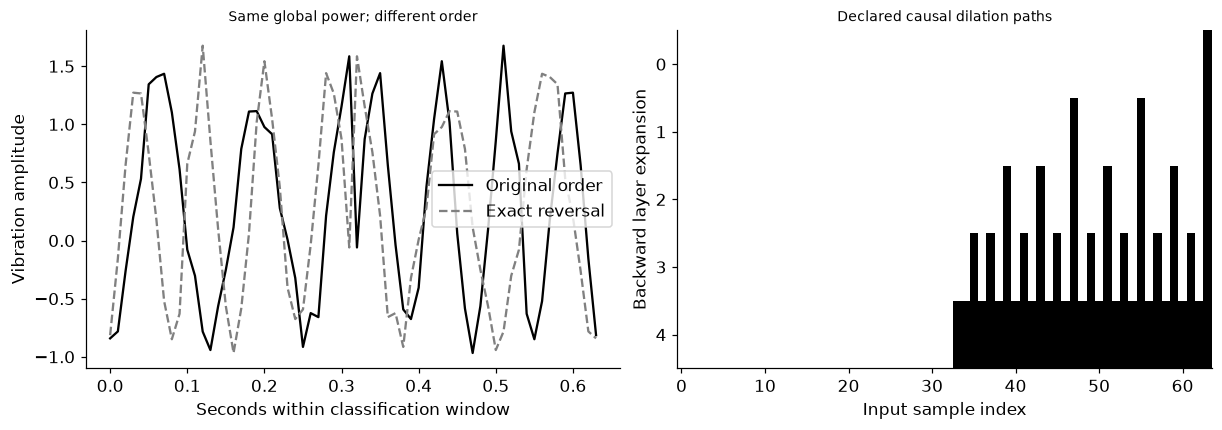

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,brier_score_loss
machine=np.repeat(np.arange(60),4);labels=np.tile([0,1,0,1],60);signals=[];sample_time=np.arange(32)/100
amplitudes=rng.uniform(.8,1.2,60);offsets=rng.normal(0,.1,60)
for i,label in enumerate(labels):
    phase=rng.uniform(0,2*np.pi,2);base=np.r_[np.sin(2*np.pi*8*sample_time+phase[0]),np.sin(2*np.pi*12*sample_time+phase[1])];wave=amplitudes[machine[i]]*base+offsets[machine[i]]+rng.normal(0,.12,64);signals.append(wave if label==0 else wave[::-1])
signals=np.array(signals);train=machine<40;dev=(machine>=40)&(machine<50);final=machine>=50
def band_features(values):
    centered=values-values.mean(1,keepdims=True);power=np.abs(np.fft.rfft(centered,axis=1))**2;frequency=np.fft.rfftfreq(values.shape[1],1/100)
    return np.column_stack([power[:,(frequency>=lo)&(frequency<hi)].sum(1) for lo,hi in [(5,10),(10,16),(16,30)]])/values.shape[1]**2
global_features=band_features(signals);ordered_features=np.column_stack([band_features(signals[:,:32]),band_features(signals[:,32:])]);rows=[]
np.testing.assert_allclose(band_features(signals[:5]),band_features(signals[:5,::-1]),atol=1e-12)
for name,values in [('Global powers',global_features),('Half-window powers',ordered_features)]:
    scaler=StandardScaler().fit(values[train]);model=LogisticRegression(C=1.,max_iter=1000).fit(scaler.transform(values[train]),labels[train]);p=model.predict_proba(scaler.transform(values[final]))[:,1];p_dev=model.predict_proba(scaler.transform(values[dev]))[:,1]
    rows.append({'method':name,'development_Brier':float(brier_score_loss(labels[dev],p_dev)),'final_Brier':float(brier_score_loss(labels[final],p)),'final_accuracy':float(accuracy_score(labels[final],p>=.5))})
center=float(signals[train].mean());scale=float(signals[train].std());x=torch.tensor((signals-center)/scale)[:,None,:];y=torch.tensor(labels,dtype=torch.float64);dilations=[1,2,4,8];receptive_field=1+2*sum(dilations)
class CausalTCN(nn.Module):
    def __init__(self):
        super().__init__();self.input=nn.Conv1d(1,8,1);self.blocks=nn.ModuleList([nn.Conv1d(8,8,3,dilation=d) for d in dilations]);self.head=nn.Conv1d(8,1,1)
    def sequence(self,z):
        h=torch.relu(self.input(z))
        for dilation,block in zip(dilations,self.blocks):h=torch.relu(h+block(nn.functional.pad(h,(2*dilation,0))))
        return self.head(h).squeeze(1)
    def forward(self,z):return self.sequence(z)[:,-1]
candidates=[]
for rate in [.005,.01]:
    torch.manual_seed(SEED);model=CausalTCN();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=float('inf');state=None
    for step in range(200):
        optimizer.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(model(x[train]),y[train]);loss.backward();optimizer.step()
        if (step+1)%10==0:
            model.eval()
            with torch.no_grad():value=float(torch.mean((torch.sigmoid(model(x[dev]))-y[dev])**2))
            if value<best:best=value;state=copy.deepcopy(model.state_dict());best_step=step+1
    model.load_state_dict(state);model.eval();candidates.append((best,rate,best_step,model))
best,rate,best_step,model=min(candidates,key=lambda v:v[0])
with torch.no_grad():p=torch.sigmoid(model(x[final])).numpy()
rows.append({'method':'Causal TCN','development_Brier':best,'final_Brier':float(brier_score_loss(labels[final],p)),'final_accuracy':float(accuracy_score(labels[final],p>=.5))})
probe=x[final][:1].clone();changed=probe.clone();changed[:,:,31:]+=3
with torch.no_grad():original_prefix=model.sequence(probe)[:,:31];changed_prefix=model.sequence(changed)[:,:31];torch.testing.assert_close(original_prefix,changed_prefix,atol=1e-12,rtol=1e-12)
# Positive linear filters audit the maximum structural field, not active paths in the trained nonlinear model.
reference=torch.ones(1,1,64,requires_grad=True);h=reference
for dilation in dilations:h=nn.functional.conv1d(nn.functional.pad(h,(2*dilation,0)),torch.ones(1,1,3),dilation=dilation)
h[0,0,-1].backward();support=np.flatnonzero(reference.grad.numpy().ravel());assert len(support)==receptive_field and support.min()==64-receptive_field
actual=probe.clone().requires_grad_();model(actual).sum().backward();gradient=actual.grad.numpy().ravel();assert np.max(np.abs(gradient[:64-receptive_field]))==0
RESULTS.update(metrics=rows,receptive_field_samples=receptive_field,first_structurally_reachable_sample=int(support.min()),sample_interval_seconds=.01,selected_TCN_rate=rate,selected_TCN_step=best_step,TCN_candidates=[{'development_Brier':b,'rate':r,'best_step':s} for b,r,s,m in candidates],TCN_parameters=sum(p.numel() for p in model.parameters()),future_prefix_max_difference=float(torch.max(torch.abs(original_prefix-changed_prefix))),global_power_reversal_max_difference=float(np.max(np.abs(band_features(signals[:5])-band_features(signals[:5,::-1])))),trained_input_gradient=gradient.tolist(),split_machines=[40,10,10])
display(pd.DataFrame(rows));print('Structural receptive field:',receptive_field,'samples')
fig,axes=plt.subplots(1,2,figsize=(11,3.8));seconds=np.arange(64)/100
axes[0].plot(seconds,signals[0],color='black',label='Original order');axes[0].plot(seconds,signals[0,::-1],'--',color='.5',label='Exact reversal');axes[0].set(xlabel='Seconds within classification window',ylabel='Vibration amplitude',title='Same global power; different order');axes[0].legend()
access=np.zeros((5,64));access[0,-1]=1;reachable={63}
for layer_index,dilation in enumerate(reversed(dilations),1):
    reachable={index-offset for index in reachable for offset in [0,dilation,2*dilation] if index-offset>=0};access[layer_index,list(reachable)]=1
axes[1].imshow(access,aspect='auto',cmap='Greys',extent=(-.5,63.5,4.5,-.5));axes[1].set(xlabel='Input sample index',ylabel='Backward layer expansion',title='Declared causal dilation paths',yticks=range(5));plt.show()


<a id="receptive-field"></a>
 ## Audit availability separately from predictive performance
 Four kernel-three, stride-one layers with dilations 1/2/4/8 have maximum field 31 samples, spanning 0.30 seconds between first and last sample. A positive linearized stack reaches all 31; trained nonlinear paths may be inactive. Future-input perturbations leave all earlier neural outputs unchanged. A global training mean is fixed during inference; per-window centering would violate that prefix contract. Both spectral baselines are permitted to use the complete classification window. The half-window baseline deliberately supplies order information. The TCN receives two learning-rate candidates and development checkpoints, while fixed-C spectral baselines do not receive an exhaustive tuning search.


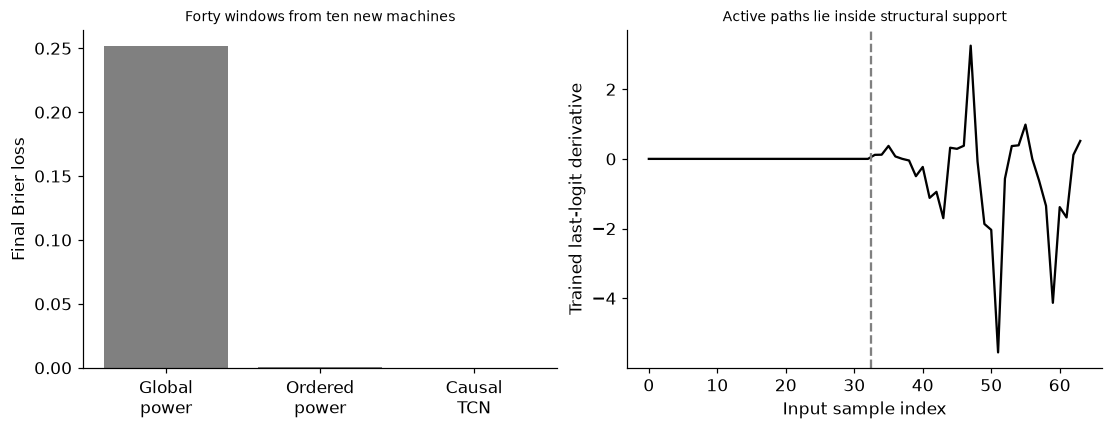

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8));xx=np.arange(3)
axes[0].bar(xx,[r['final_Brier'] for r in rows],color='.5');axes[0].set(xticks=xx,xticklabels=['Global\npower','Ordered\npower','Causal\nTCN'],ylabel='Final Brier loss',title='Forty windows from ten new machines')
axes[1].plot(np.arange(64),gradient,color='black');axes[1].axvline(64-receptive_field-.5,linestyle='--',color='.5');axes[1].set(xlabel='Input sample index',ylabel='Trained last-logit derivative',title='Active paths lie inside structural support');plt.show()
assert all(0<=r['final_Brier']<=1 for r in rows)


In [4]:
summary={'example_id':'code_109','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual causal Conv1d model', 'dilation and receptive field', 'spectral order invariance', 'whole-machine holdout', 'future-input perturbation audit'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual causal Conv1d model", "dilation and receptive field", "spectral order invariance", "whole-machine holdout", "future-input perturbation audit"], "elapsed_seconds": 3.231, "example_id": "code_109", "hardware": "Darwin arm64 CPU", "results": {"TCN_candidates": [{"best_step": 200, "development_Brier": 1.927355265762106e-06, "rate": 0.005}, {"best_step": 200, "development_Brier": 1.1420725860554361e-11, "rate": 0.01}], "TCN_parameters": 825, "first_structurally_reachable_sample": 33, "future_prefix_max_difference": 0.0, "global_power_reversal_max_difference": 5.551115123125783e-17, "metrics": [{"development_Brier": 0.24418927932623732, "final_Brier": 0.2514248494910469, "final_accuracy": 0.475, "method": "Global powers"}, {"development_Brier": 0.00045283885372521016, "final_Brier": 0.0002941100413354398, "final_accuracy": 1.0, "method": "Half-window powers"}, {"development_Brier": 1.1420725860554361e-11, "final_Brier": 9.001642543080